# Departure Slot Capacity Planning

*© 2026 Taras Bulubas — all rights reserved. You may open, run and modify this
notebook in Google Colab for personal, non-commercial exploration; any other
use requires prior written permission. See `LICENSE`.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tbulubas/departure-slot-planning/blob/main/notebooks/slot_capacity.ipynb)

Departures compete for 10-minute departure slots of limited capacity. This
notebook plans them with a time-indexed MILP (**OR-Tools + SCIP**) and
compares two delay costs: the **quadratic** cost $d^2$ and the **falling
trees** model $d/(1+q)$. You can change NOW, the planned departures and the
capacity of every single slot.

**Where it runs:** in Google Colab with the badge above (the first code cell
installs the package from GitHub, about half a minute), or locally in the
project's `.venv`.

**How to use it**

1. Run all cells once: *Run → Run All Cells* (in Google Colab: *Runtime →
   Run all*).
2. Change the input in [section 4](#4-input) and run the cells from there on
   again, or use the interactive explorer in [section 10](#10-interactive-explorer).

**Contents**

1. [The problem](#1-the-problem)
2. [Two delay costs](#2-two-delay-costs)
3. [Setup](#3-setup)
4. [Input](#4-input)
5. [Solve with both costs](#5-solve-with-both-costs)
6. [How the flights are pushed into the slots](#6-how-the-flights-are-pushed-into-the-slots)
7. [Slot prices — the pressure on a slot](#7-slot-prices--the-pressure-on-a-slot)
8. [NOW moves on](#8-now-moves-on)
9. [A long planning window](#9-a-long-planning-window)
10. [Interactive explorer](#10-interactive-explorer)

## 1. The problem

At the planning moment **NOW** every flight $i$ has a planned departure
time $T(p)_i$. The departure capacity is given per **slot** of 10 minutes;
slots are aligned to the full hour (06:00, 06:10, …) and the grid starts at
the beginning of the hour containing NOW. Every slot has its own capacity —
e.g. 3 departures normally, 1 during a runway inspection, 0 when closed.

The plan gives every flight a slot, or a **parking slot** with unlimited
capacity when the window is full. A flight

- never departs before its planned time (it may take the slot containing
  $T(p)_i$ or a later one),
- is never planned or sequenced before **NOW** — a hard limit: $T(p)_i \ge$
  NOW and $T(s)_i \ge$ NOW,
- departs at its **sequenced time** $T(s)_i$ = the slot start, but not before
  $T(p)_i$ and not before NOW,
- is delayed by $d_i = T(s)_i - T(p)_i \ge 0$.

Goal: as little delay as possible — for every flight and for the airport as
a whole — without delaying one flight heavily so that others can go on
time.

## 2. Two delay costs

| cost | $f(d)$ | slope $f'(d)$ — the pressure |
|---|---|---|
| quadratic | $d^2$ | $2d$, grows with the delay |
| falling trees | $\dfrac{d}{1 + q/\tau}$ | $\dfrac{1}{1 + q/\tau}$, constant per flight |

$q_i = T(p)_i - \text{NOW} \ge 0$ is the lead time: minutes from NOW to
the planned departure. In the falling trees model every flight is a straight
line rising from its planned time; the later it is planned, the flatter the
line — like trees felled by a blast. With $\tau = 1$ minute the cost is
$d/(1+q)$.

**The model** (details in `docs/mip-model.md`): a binary $x_{ik}$ for every
flight $i$ and every slot $k$ it may take, plus parking $P$:

$$\min \sum_i \sum_{k} c_{ik}\, x_{ik} \quad\text{s.t.}\quad
\sum_k x_{ik} = 1 \;\;\forall i, \qquad \sum_i x_{ik} \le C_k \;\;\forall k,$$

with $c_{ik} = f(d_{ik})$ computed in advance. The shape of $f$ does not
change the structure of the model at all.

## 3. Setup

The first cell installs the `slot_capacity` package from GitHub if it is not
available yet (e.g. in Google Colab). The second cell imports it.

In [1]:
import importlib
import importlib.util
import subprocess
import sys

REPOSITORY = "https://github.com/tbulubas/departure-slot-planning.git"

if importlib.util.find_spec("slot_capacity") is None:
    print("Installing the slot_capacity package from GitHub …")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", f"slot-capacity[plot] @ git+{REPOSITORY}"]
    )
    importlib.invalidate_caches()
    print("done")
else:
    print("slot_capacity is already installed")

slot_capacity is already installed


In [2]:
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import ortools
from slot_capacity import (FALLING_TREES, QUADRATIC, Objective, SlotInstance, coefficient_range,
                           format_time, metrics, rows, slot_prices, solve, verify)
from slot_capacity.draw import plot_plan, plot_prices
from slot_capacity.instance import EXAMPLE_CAPACITIES, EXAMPLE_FLIGHTS

print(f"Python {sys.version.split()[0]}  ·  OR-Tools {ortools.__version__}")

Python 3.12.10  ·  OR-Tools 9.15.6755


## 4. Input

Times are `HH:MM`. `SLOT_CAPACITY` overrides the capacity of single slots,
keyed by the slot start (a multiple of 10 minutes). `END = None` ends the
window one full hour after the latest planned departure. A parked flight
counts as departing `PARKING_DELAY` minutes after the end of the window.

The example is a morning bank of 24 departures with a runway inspection in
the peak: only one departure in the slots 06:30 and 06:40, two in 06:50.

In [3]:
NOW = "06:00"
FLIGHTS = list(EXAMPLE_FLIGHTS)          # or e.g. ["06:05", "06:05", "06:12", ...]
DEFAULT_CAPACITY = 3                     # departures per 10-minute slot
SLOT_CAPACITY = dict(EXAMPLE_CAPACITIES)  # e.g. {"06:30": 1, "06:40": 0}
END = None                               # e.g. "09:00"
PARKING_DELAY = 60                       # minutes after the end of the window
TAU = 1.0                                # time scale of the falling trees, minutes

instance = SlotInstance.create(NOW, FLIGHTS, default_capacity=DEFAULT_CAPACITY,
                               capacities=SLOT_CAPACITY, end=END, parking_delay=PARKING_DELAY)
print(f"NOW {format_time(instance.now)}, window {format_time(instance.start)}–{format_time(instance.window_end)}, "
      f"{len(instance.flights)} flights, {len(instance.slots)} slots")
pd.DataFrame(
    {s.label: [s.capacity, sum(1 for f in instance.flights if s.start <= f.planned < s.end),
               "past" if instance.is_past(s) else ""] for s in instance.slots},
    index=["capacity", "planned in slot", ""],
)

NOW 06:00, window 06:00–09:00, 24 flights, 18 slots


,06:00,06:10,06:20,06:30,06:40,06:50,07:00,07:10,07:20,07:30,07:40,07:50,08:00,08:10,08:20,08:30,08:40,08:50
capacity,3,3,3,1,1,2,3,3,3,3,3,3,3,3,3,3,3,3
planned in slot,3,2,3,5,4,3,2,1,1,0,0,0,0,0,0,0,0,0
,,,,,,,,,,,,,,,,,,


## 5. Solve with both costs

Each plan is checked by an independent `verify()`.

In [4]:
objectives = {"quadratic": Objective(QUADRATIC), "falling trees": Objective(FALLING_TREES, TAU)}
plans = {label: solve(instance, o) for label, o in objectives.items()}
for label, plan in plans.items():
    print(f"{label:14s} {plan.status}, objective {plan.value:.6g}, {plan.seconds:.2f} s, "
          f"{plan.variables} variables, {plan.constraints} constraints, check: {verify(instance, plan) or 'OK'}")

table = {}
for label, plan in plans.items():
    for r in rows(instance, plan):
        key = (r.flight.name, format_time(r.flight.planned))
        table.setdefault(key, {})[(label, "slot")] = "park" if r.parked else instance.slots[r.slot].label
        table[key][(label, "delay")] = r.delay
        table[key][(label, "cost")] = round(r.cost, 4)
df = pd.DataFrame.from_dict(table, orient="index")
df.index.names = ["flight", "T(p)"]
df

quadratic      optimal, objective 6067, 0.00 s, 375 variables, 42 constraints, check: OK
falling trees  optimal, objective 6.00706, 0.00 s, 375 variables, 42 constraints, check: OK


quadratic            falling trees              
                  slot delay cost          slot delay    cost
flight T(p)                                                  
F01    06:02     06:00     0    0         06:00     0  0.0000
F02    06:05     06:00     0    0         06:00     0  0.0000
F03    06:08     06:00     0    0         06:00     0  0.0000
F04    06:14     06:10     0    0         06:10     0  0.0000
F05    06:18     06:10     0    0         06:10     0  0.0000
F06    06:21     06:20     0    0         06:20     0  0.0000
F07    06:25     06:20     0    0         06:20     0  0.0000
F08    06:28     06:20     0    0         06:20     0  0.0000
F09    06:30     06:30     0    0         06:30     0  0.0000
F10    06:31     06:40     9   81         06:40     9  0.2812
F11    06:34     06:50    16  256         06:50    16  0.4571
F12    06:36     06:50    14  196         06:50    14  0.3784
F13    06:38     07:00    22  484         07:00    22  0.5641
F14    06:40     07:00    20  400         07:00    20  0.4878
F15    06:41     07:00    19  361         07:00    19  0.4524
F16    06:44     07:10    26  676         07:10    26  0.5778
F17    06:47     07:10    23  529         07:10    23  0.4792
F18    06:50     07:10    20  400         07:10    20  0.3922
F19    06:52     07:20    28  784         07:20    28  0.5283
F20    06:55     07:20    25  625         07:20    25  0.4464
F21    07:00     07:20    20  400         07:20    20  0.3279
F22    07:05     07:30    25  625         07:30    25  0.3788
F23    07:15     07:30    15  225         07:30    15  0.1974
F24    07:25     07:30     5   25         07:30     5  0.0581

In [5]:
pd.DataFrame({label: vars(metrics(instance, plan, TAU)) for label, plan in plans.items()})

,quadratic,falling trees
total_delay,287.000000,287.000000
max_delay,28.000000,28.000000
delayed,15.000000,15.000000
parked,0.000000,0.000000
overtakes,0.000000,0.000000
quadratic,6067.000000,6067.000000
falling_trees,6.007056,6.007056


Both costs give the same delays and keep the planned order (0
overtakes): the total delay of the airport is minimal and nobody is
sacrificed. The difference is in *how hard* the flights push.

## 6. How the flights are pushed into the slots

Top: departures per slot against the capacity (red = full). Middle: one row
per flight, ○ planned time, ■ sequenced time, the arrow is the delay.
Bottom: the price of each slot (section 7).

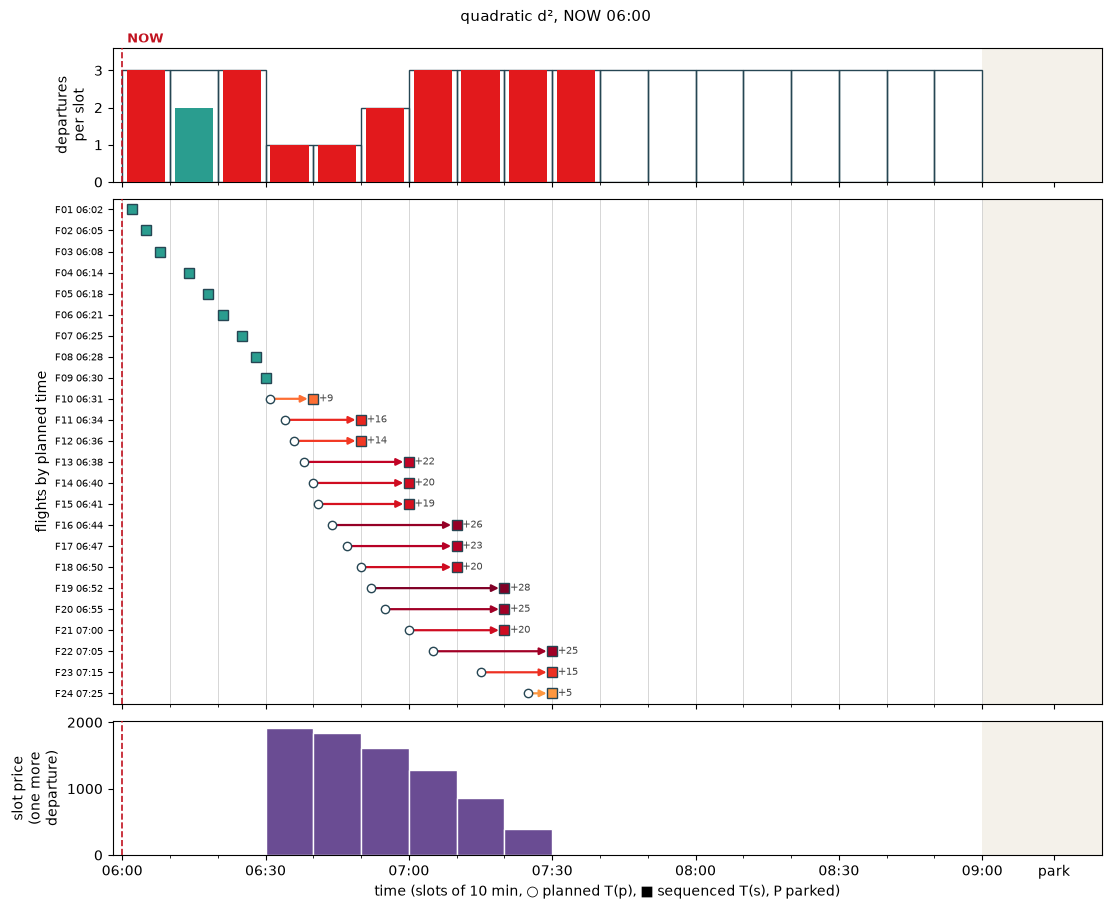

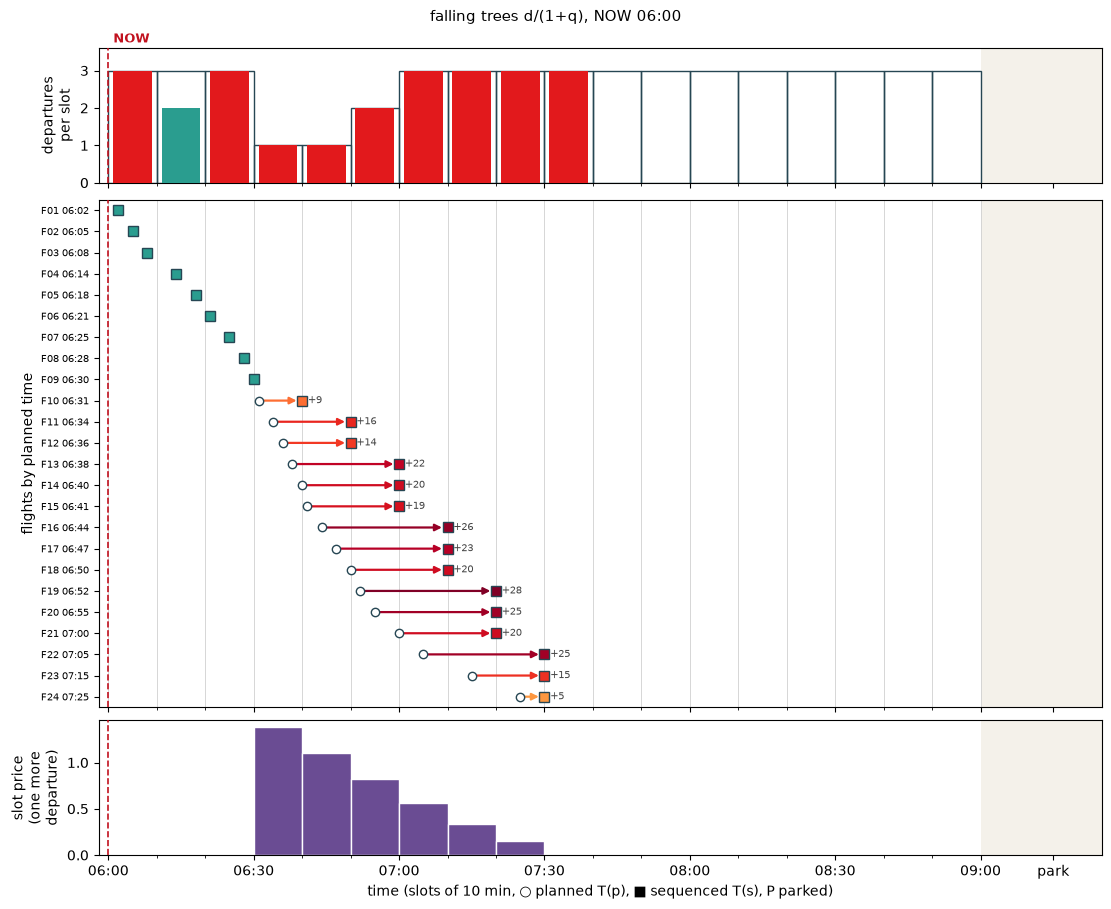

In [6]:
prices = {label: slot_prices(instance, o) for label, o in objectives.items()}
for label, plan in plans.items():
    fig = plot_plan(instance, plan, prices[label], title=f"{objectives[label].label}, NOW {NOW}")
    plt.show()

## 7. Slot prices — the pressure on a slot

The price of a slot is what **one more departure** in it would save: the
flights queued behind it all move up by one place. It equals the dual value
of the capacity constraint. The step between two consecutive full slots is
the cost of moving the flight at their border by one slot — slot length ×
its slope for falling trees, $f(d) - f(d-10)$ for the quadratic cost. So the
price adds up the pressure of the whole queue.

In [7]:
pd.DataFrame(
    {label: {instance.slots[k].label: round(v, 4) for k, v in p.items()} for label, p in prices.items()}
).T

,06:00,06:10,06:20,06:30,06:40,06:50,07:00,07:10,07:20,07:30,07:40,07:50,08:00,08:10,08:20,08:30,08:40,08:50
quadratic,0.0,0.0,0.0,1921.0000,1840.0000,1620.0000,1280.0000,860.0000,400.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
falling trees,0.0,0.0,0.0,1.3858,1.1045,0.8188,0.5624,0.3402,0.1515,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


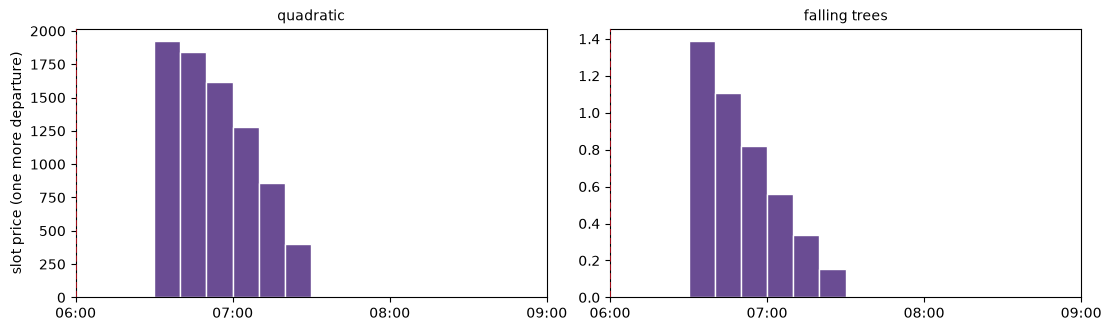

In [8]:
fig = plot_prices(instance, prices)
plt.show()

## 8. NOW moves on

The same flights and capacities, planned at different moments NOW (always
before the first planned departure — NOW is a hard limit). The quadratic
cost does not know NOW: its plan and its prices stay the same. In the
falling trees model the lead times $q = T(p) - \text{NOW}$ shrink as NOW
approaches the bank, the trees stand up and the slots near NOW get more
expensive — while the plan itself stays first planned, first served.

In [9]:
moments = ["04:00", "05:00", "05:30", "06:00"]
price_rows, metric_rows = {}, {}
for moment in moments:
    inst = SlotInstance.create(moment, FLIGHTS, default_capacity=DEFAULT_CAPACITY, capacities=SLOT_CAPACITY,
                               end=END, parking_delay=PARKING_DELAY)
    for label, o in objectives.items():
        plan = solve(inst, o)
        m = metrics(inst, plan, TAU)
        metric_rows[(moment, label)] = {"total delay": m.total_delay, "max delay": m.max_delay,
                                        "overtakes": m.overtakes, "objective": round(plan.value, 4)}
        p = slot_prices(inst, o)
        price_rows[(moment, label)] = {s.label: round(p.get(s.index, 0.0), 4) for s in inst.slots
                                       if "06:30" <= s.label <= "07:20"}
display(pd.DataFrame.from_dict(metric_rows, orient="index").rename_axis(["NOW", "cost"]))
pd.DataFrame.from_dict(price_rows, orient="index").rename_axis(["NOW", "cost"])

total delay  max delay  overtakes  objective
NOW   cost                                                       
04:00 quadratic              287         28          0  6067.0000
      falling trees          287         28          0     1.6925
05:00 quadratic              287         28          0  6067.0000
      falling trees          287         28          0     2.6294
05:30 quadratic              287         28          0  6067.0000
      falling trees          287         28          0     3.6460
06:00 quadratic              287         28          0  6067.0000
      falling trees          287         28          0     6.0071

06:30      06:40      06:50      07:00     07:10  \
NOW   cost                                                                  
04:00 quadratic      1921.0000  1840.0000  1620.0000  1280.0000  860.0000   
      falling trees     0.3588     0.2996     0.2351     0.1722    0.1116   
05:00 quadratic      1921.0000  1840.0000  1620.0000  1280.0000  860.0000   
      falling trees     0.5672     0.4694     0.3641     0.2631    0.1679   
05:30 quadratic      1921.0000  1840.0000  1620.0000  1280.0000  860.0000   
      falling trees     0.8019     0.6568     0.5029     0.3580    0.2246   
06:00 quadratic      1921.0000  1840.0000  1620.0000  1280.0000  860.0000   
      falling trees     1.3858     1.1045     0.8188     0.5624    0.3402   

                        07:20  
NOW   cost                     
04:00 quadratic      400.0000  
      falling trees    0.0538  
05:00 quadratic      400.0000  
      falling trees    0.0794  
05:30 quadratic      400.0000  
      falling trees    0.1042  
06:00 quadratic      400.0000  
      falling trees    0.1515

## 9. A long planning window

The objective sums over all flights of the window. The longer the window,
the longer the possible delays — and the larger the coefficients. For the
quadratic cost the largest one grows with the square of the window, for
falling trees linearly. A MIP solver stops at a *relative* gap, so huge
coefficients from the far end of the window make the near-term decisions
invisible.

In [10]:
ranges = []
for hours in (3, 6, 12, 18):
    end = instance.start + 60 * hours
    inst = SlotInstance.create(NOW, FLIGHTS, default_capacity=DEFAULT_CAPACITY, capacities=SLOT_CAPACITY,
                               end=format_time(end), parking_delay=PARKING_DELAY)
    row = {"window (h)": hours}
    for label, o in objectives.items():
        r = coefficient_range(inst, o)
        row[f"{label}: smallest"] = r.smallest
        row[f"{label}: largest"] = r.largest
        row[f"{label}: ratio"] = r.ratio
    ranges.append(row)
pd.DataFrame(ranges).set_index("window (h)").style.format("{:.3g}")

,quadratic: smallest,quadratic: largest,quadratic: ratio,falling trees: smallest,falling trees: largest,falling trees: ratio
window (h),,,,,,
3,4,5.66e+04,1.42e+04,0.0513,79.3,1.55e+03
6,4,1.75e+05,4.37e+04,0.0513,139,2.72e+03
12,4,6.05e+05,1.51e+05,0.0513,259,5.06e+03
18,4,1.3e+06,3.24e+05,0.0513,379,7.4e+03


## 10. Interactive explorer

Set NOW, the planned departures and the default capacity, press **Slots**
to get one slider per slot, adjust the capacities and press **Solve**. This
needs a running kernel (it does not work in a static view of the
notebook).

In [11]:
import ipywidgets as w

now_w = w.Text(value=NOW, description="NOW")
end_w = w.Text(value="" if END is None else END, description="END", placeholder="auto")
flights_w = w.Textarea(value=", ".join(FLIGHTS), description="T(p)", layout=w.Layout(width="720px", height="70px"))
default_w = w.IntSlider(value=DEFAULT_CAPACITY, min=0, max=6, description="capacity")
objective_w = w.Dropdown(options=list(objectives), value="falling trees", description="cost")
tau_w = w.FloatText(value=TAU, description="τ (min)")
parking_w = w.IntText(value=PARKING_DELAY, description="parking +")
slots_button = w.Button(description="Slots", icon="sliders")
solve_button = w.Button(description="Solve", button_style="primary", icon="play")
sliders_box = w.HBox(layout=w.Layout(flex_flow="row wrap"))
output = w.Output()
sliders = {}


def current_instance(capacities):
    flights = [t.strip() for t in flights_w.value.replace(";", ",").split(",") if t.strip()]
    return SlotInstance.create(now_w.value, flights, default_capacity=default_w.value, capacities=capacities,
                               end=end_w.value.strip() or None, parking_delay=parking_w.value)


def on_slots(_=None):
    with output:
        output.clear_output()
        try:
            inst = current_instance({**SLOT_CAPACITY})
        except ValueError as error:
            print(f"Invalid input: {error}")
            return
    sliders.clear()
    for s in inst.slots:
        if not inst.is_past(s):
            sliders[s.label] = w.IntSlider(value=s.capacity, min=0, max=6, orientation="vertical",
                                           description=s.label, layout=w.Layout(width="52px", height="150px"))
    sliders_box.children = list(sliders.values())


def on_solve(_):
    with output:
        output.clear_output(wait=True)
        try:
            inst = current_instance({label: s.value for label, s in sliders.items()})
            o = Objective(QUADRATIC) if objective_w.value == "quadratic" else Objective(FALLING_TREES, tau_w.value)
        except ValueError as error:
            print(f"Invalid input: {error}")
            return
        plan = solve(inst, o)
        m = metrics(inst, plan, tau_w.value)
        print(f"{o.label}: {plan.status}, objective {plan.value:.6g}; total delay {m.total_delay} min, "
              f"max {m.max_delay} min, {m.parked} parked, {m.overtakes} overtakes; "
              f"check: {verify(inst, plan) or 'OK'}")
        plot_plan(inst, plan, slot_prices(inst, o), title=f"{o.label}, NOW {now_w.value}")
        plt.show()


slots_button.on_click(on_slots)
solve_button.on_click(on_solve)
on_slots()
display(w.VBox([w.HBox([now_w, end_w, parking_w]), flights_w, w.HBox([default_w, objective_w, tau_w]),
                w.HBox([slots_button, solve_button]), sliders_box, output]))

## Things to try

| Try | What happens |
|---|---|
| set the slot 06:30 to 0 | the queue behind it gets longer, all prices behind it rise |
| NOW = 05:00 | falling trees prices drop, the plan stays (section 8) |
| a flight planned before NOW | rejected: NOW is a hard limit |
| capacity 1 everywhere | a long queue: the quadratic prices explode, falling trees stays small |
| `END` = "07:00" | the window is too short: flights are parked |
| τ = 30 | the trees fall slower: slopes of near and far flights get closer |